# 00 · Preprocesamiento: del registro de SUTRAN a los datasets limpios

**Proyecto:** Predicción del riesgo y la gravedad de accidentes en carreteras del Perú con datos abiertos y clima.

Este notebook hace la preparación de los datos **antes** del EDA y documenta cada decisión:
1. lectura y limpieza del registro de accidentes (SUTRAN);
2. ubicación de cada accidente con su vía y kilómetro (Red Vial Nacional del MTC);
3. clima diario en la celda del accidente (Open-Meteo);
4. atributos de la vía del tramo (MTC);
5. clima por hora y condición de luz (Open-Meteo);
6. variables derivadas (calendario, distancia a la capital);
7. **selección de variables y encoding** (decisiones del grupo);
8. **dataset final** de la Tarea 2: una fila por accidente, solo identificación, objetivo y variables;
9. **panel** departamento × día de la Tarea 1, con los días sin accidentes.

Las funciones están en `src/preprocessing.py`. `python -m src.preprocessing` produce las mismas dos salidas sin el
notebook. Las descargas externas quedan en caché en `data/raw/`, así que el notebook corre sin internet.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# Raíz del repo (funciona si el notebook se ejecuta desde /notebooks o desde la raíz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import preprocessing as pp

PLOTS = ROOT / "results" / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)

## 1. Datos de accidentes (SUTRAN)

**Decisión:** leer todo como texto (`dtype=str`), porque los faltantes vienen como `"N.I."` y no como celdas vacías.

In [2]:
raw = pp.leer_accidentes()
print(f"{raw.shape[0]:,} accidentes × {raw.shape[1]} columnas")
raw.head()

8,155 accidentes × 9 columnas


,FECHA_CORTE,FECHA,HORA,DEPARTAMENTO,CODIGO_VIA,KILOMETRO,MODALIDAD,NUM_FALLECIDOS,NUM_HERIDOS
0,20211222,20200101,05:40,LIMA,PE-1S,24,DESPISTE,0,0
1,20211222,20200101,16:30,CAJAMARCA,PE-3N,74,DESPISTE,0,0
2,20211222,20200101,07:45,PASCO,PE-3N,103,DESPISTE,0,1
3,20211222,20200101,18:30,CAJAMARCA,PE-08,111,DESPISTE,0,2
4,20211222,20200101,18:40,LIMA,PE-1N,174,DESPISTE,0,5


### 1.1 Calidad del archivo crudo

In [3]:
display(pp.resumen_faltantes(raw))
print("FECHA_CORTE (valores distintos):", raw["FECHA_CORTE"].unique().tolist())
print("Rango de FECHA:", raw["FECHA"].min(), "→", raw["FECHA"].max())
print("Modalidades:", sorted(raw["MODALIDAD"].unique()))
print("\nDepartamentos tal como vienen en el crudo:")
print(raw["DEPARTAMENTO"].value_counts().to_string())

,vacios,N.I.,% faltante
FECHA_CORTE,0,0,0.00
FECHA,0,0,0.00
HORA,0,88,1.08
DEPARTAMENTO,0,7,0.09
CODIGO_VIA,0,46,0.56
KILOMETRO,0,45,0.55
MODALIDAD,0,28,0.34
NUM_FALLECIDOS,0,3,0.04
NUM_HERIDOS,0,10,0.12


FECHA_CORTE (valores distintos): ['20211222']
Rango de FECHA: 20200101 → 20210930
Modalidades: ['ATROPELLO', 'CHOQUE', 'DESPISTE', 'ESPECIAL', 'N.I.', 'VOLCADURA']

Departamentos tal como vienen en el crudo:
DEPARTAMENTO
LIMA             1558
AREQUIPA          795
JUNIN             715
ANCASH            602
PUNO              529
ICA               377
CAJAMARCA         350
CUSCO             346
LAMBAYEQUE        343
LA LIBERTAD       329
PIURA             327
SAN MARTIN        274
APURIMAC          202
MADRE DE DIOS     191
HUANUCO           174
AYACUCHO          168
MOQUEGUA          155
UCAYALI           154
AMAZONAS          152
TACNA             151
LORETO             82
PASCO              77
HUANCAVELICA       62
TUMBES             25
N.I.                7
CALLAO              6
Arequipa            2
Puno                1
Cusco               1


**Hallazgos**
- Faltantes ≤ 1.1 % por columna; `NUM_FALLECIDOS` solo falta en 3.
- Periodo real: enero 2020 – septiembre 2021 (la `FECHA_CORTE` es posterior).
- Departamentos escritos de dos formas (`AREQUIPA` / `Arequipa`): hay que normalizar.

### 1.2 Limpieza

| Problema | Decisión | Por qué |
|---|---|---|
| `NUM_FALLECIDOS` = N.I. (3) | Descartar | Es parte del objetivo. |
| `DEPARTAMENTO` = N.I. (7) | Descartar | Sin él no se asigna clima ni panel. |
| Duplicados exactos (35) | Descartar | Doble registro; duplicaría víctimas. |
| `HORA`, `CODIGO_VIA`, `KILOMETRO`, `MODALIDAD` = N.I. | Conservar | Se marcan como faltantes o 'SIN DATO'; los modelos los manejan. |
| `NUM_HERIDOS` = N.I. (10) | 0 para contar; `GRAVEDAD` desconocida si tampoco hubo fallecidos (5) | Esos 5 salen del dataset final: no se sabe su clase. |
| Tildes y mayúsculas | Normalizar | Unificar departamentos (`AREQUIPA` / `Arequipa`). |

Se derivan `HORA_INT`, `MES`, `DIA_SEMANA` y el objetivo `GRAVEDAD` (0 sin víctimas, 1 heridos, 2 al menos un fallecido).

In [4]:
df, bitacora = pp.limpiar_accidentes(raw)
display(bitacora)

print(f"Registros finales: {len(df):,} ({100 * len(df) / len(raw):.1f} % del crudo)")
print("Periodo:", df.FECHA.min().date(), "→", df.FECHA.max().date())
print("Departamentos tras normalizar:", df.DEPARTAMENTO.nunique())
print("\nFaltantes que se conservan:")
print(f"  hora N.I.:      {df.HORA_INT.isna().sum()}")
print(f"  vía N.I.:       {(df.CODIGO_VIA == pp.NI).sum()}")
print(f"  kilómetro N.I.: {df.KILOMETRO.isna().sum()}")
print(f"  modalidad N.I.: {(df.MODALIDAD == pp.NI).sum()}")

,paso,antes,descartados,despues,decision
0,Fecha inválida o sin dato de fallecidos,8155,3,8152,Descartar: sin variable objetivo
1,Departamento 'N.I.',8152,7,8145,Descartar: no se puede asignar lluvia
2,Duplicados exactos,8145,35,8110,Descartar: mismo registro repetido


Registros finales: 8,110 (99.4 % del crudo)
Periodo: 2020-01-01 → 2021-09-30
Departamentos tras normalizar: 25

Faltantes que se conservan:
  hora N.I.:      86
  vía N.I.:       39
  kilómetro N.I.: 43
  modalidad N.I.: 26


In [5]:
# Ejemplos de duplicados exactos en el crudo: cada par es idéntico en todas las columnas
dups = raw[raw.duplicated(keep=False)].sort_values(["FECHA", "HORA", "CODIGO_VIA"])
print(f"Filas involucradas: {len(dups)} ({raw.duplicated().sum()} sobrantes)")
dups.head(6)

Filas involucradas: 70 (35 sobrantes)


,FECHA_CORTE,FECHA,HORA,DEPARTAMENTO,CODIGO_VIA,KILOMETRO,MODALIDAD,NUM_FALLECIDOS,NUM_HERIDOS
219,20211222,20200115,17:40,JUNIN,PE-3S,62,DESPISTE,0,1
220,20211222,20200115,17:40,JUNIN,PE-3S,62,DESPISTE,0,1
279,20211222,20200118,12:30,PUNO,PE-34A,272,DESPISTE,0,0
280,20211222,20200118,12:30,PUNO,PE-34A,272,DESPISTE,0,0
439,20211222,20200128,04:00,JUNIN,PE-3S,74,DESPISTE,0,0
440,20211222,20200128,04:00,JUNIN,PE-3S,74,DESPISTE,0,0


Quedan **8 110 accidentes** (−0.6 %).

### 1.3 Valores extremos

In [6]:
print("Distribución de fallecidos por accidente:")
print(df.NUM_FALLECIDOS.value_counts().sort_index().to_string())
print("\nAccidentes con 10 o más fallecidos:")
df.loc[df.NUM_FALLECIDOS >= 10, ["FECHA", "HORA", "DEPARTAMENTO", "CODIGO_VIA", "KILOMETRO", "MODALIDAD",
                                  "NUM_FALLECIDOS", "NUM_HERIDOS"]]

Distribución de fallecidos por accidente:
NUM_FALLECIDOS
0     7159
1      775
2      111
3       30
4       12
5        7
6        4
7        2
9        1
11       3
16       2
18       1
20       1
22       1
33       1

Accidentes con 10 o más fallecidos:


,FECHA,HORA,DEPARTAMENTO,CODIGO_VIA,KILOMETRO,MODALIDAD,NUM_FALLECIDOS,NUM_HERIDOS
91,2020-01-06,00:20,AREQUIPA,PE-1S,571.0,CHOQUE,16,46.0
2000,2020-07-26,17:00,LA LIBERTAD,LI-122,86.0,DESPISTE,11,2.0
3730,2020-12-14,16:30,PUNO,PE-34A,192.0,CHOQUE,11,12.0
5349,2021-04-08,07:25,AYACUCHO,PE-30A,238.0,DESPISTE,11,21.0
5397,2021-04-12,07:00,ANCASH,PE-14C,49.0,DESPISTE,20,17.0
6214,2021-06-08,12:40,LA LIBERTAD,LI-127,0.0,DESPISTE,18,5.0
6362,2021-06-18,03:30,AYACUCHO,PE-30A,40.0,DESPISTE,22,17.0
7528,2021-08-27,12:30,APURIMAC,PE-3SF,350.0,DESPISTE,16,2.0
7606,2021-08-31,04:15,LIMA,PE-22,72.0,DESPISTE,33,29.0


**Decisión:** conservar los 9 accidentes con ≥ 10 fallecidos: son reales (despistes y choques con muchos heridos) y son los casos más graves. Su efecto se revisa en 4.3.

In [7]:
# KILOMETRO es la distancia desde el inicio de CADA vía, no una coordenada
km = df.groupby("CODIGO_VIA").KILOMETRO.agg(accidentes="count", km_min="min", km_max="max")
print(df.KILOMETRO.describe().round(1).to_string())
km.sort_values("km_max", ascending=False).head(6)

count    8067.0
mean      291.0
std       336.7
min         0.0
25%        56.0
50%       139.0
75%       411.0
max      1814.0


,accidentes,km_min,km_max
CODIGO_VIA,,,
PE-3N,471,0.0,1814.0
PE-1S,1400,0.0,1497.0
PE-3S,634,0.0,1495.0
PE-5N,435,0.0,1492.0
PE-3SA,49,1.0,1430.0
PE-1NJ,142,1.0,1338.0


El kilómetro solo tiene sentido dentro de cada vía. **Decisión:** no usarlo solo; en la sección 2 se convierte en coordenadas.

## 2. Ubicación: vía + kilómetro → coordenadas

**Decisiones**
- **Fuente:** Red Vial Nacional del MTC (2014): cada tramo trae ruta, km inicial y final, y departamento.
- **Método:** interpolar el kilómetro a lo largo del tramo (la longitud de los tramos coincide con su kilometraje, mediana 0.99). Se corrigen los tramos dibujados al revés.
- **Validación:** el punto solo se acepta si cae en el departamento del accidente (o a ≤ 10 km de su límite).
- **Respaldo:** si no, la capital del departamento. La columna `UBICACION` (`km` / `capital`) indica cuál se usó.

In [8]:
tramos = pp.cargar_red_vial()
print(f"Red vial: {len(tramos):,} tramos de {len({t['ruta'] for t in tramos})} rutas nacionales")

df = df.join(pp.ubicar_accidentes(df, tramos))
motivos = (df.groupby(["UBICACION", "MOTIVO_UBICACION"]).size().rename("accidentes").reset_index()
           .sort_values(["UBICACION", "accidentes"], ascending=[False, False]))
motivos["%"] = (100 * motivos.accidentes / len(df)).round(1)
display(motivos)
print(df.UBICACION.value_counts(normalize=True).mul(100).round(1).to_string())

Red vial: 3,465 tramos de 141 rutas nacionales


,UBICACION,MOTIVO_UBICACION,accidentes,%
6,km,tramo en el departamento,6411,79.1
7,km,tramo en el departamento vecino (frontera),91,1.1
3,capital,tramo en otro departamento (km no coincide con...,1059,13.1
5,capital,vía departamental o vecinal,229,2.8
1,capital,kilómetro fuera de los tramos de la ruta,228,2.8
4,capital,vía N.I.,39,0.5
0,capital,kilómetro N.I.,35,0.4
2,capital,ruta no está en la capa del MTC,18,0.2


UBICACION
km         80.2
capital    19.8


**Hallazgo:** **80.2 %** ubicado por km. Del resto, 1 059 tienen un km que no coincide con el kilometraje del MTC (hitos antiguos), 229 están en vías departamentales y el resto no tiene vía o km válidos.

Distancia del punto ubicado a la capital de su departamento (km):
count    6502.0
mean       81.4
std        60.4
min         0.2
25%        40.7
50%        72.9
75%       104.2
90%       142.9
max       385.9

Mediana por departamento (km):
DEPARTAMENTO
SAN MARTIN       243.0
JUNIN            101.0
ANCASH            90.0
MADRE DE DIOS     88.0
CUSCO             83.0
LIMA              79.0
AREQUIPA          75.0
PUNO              75.0


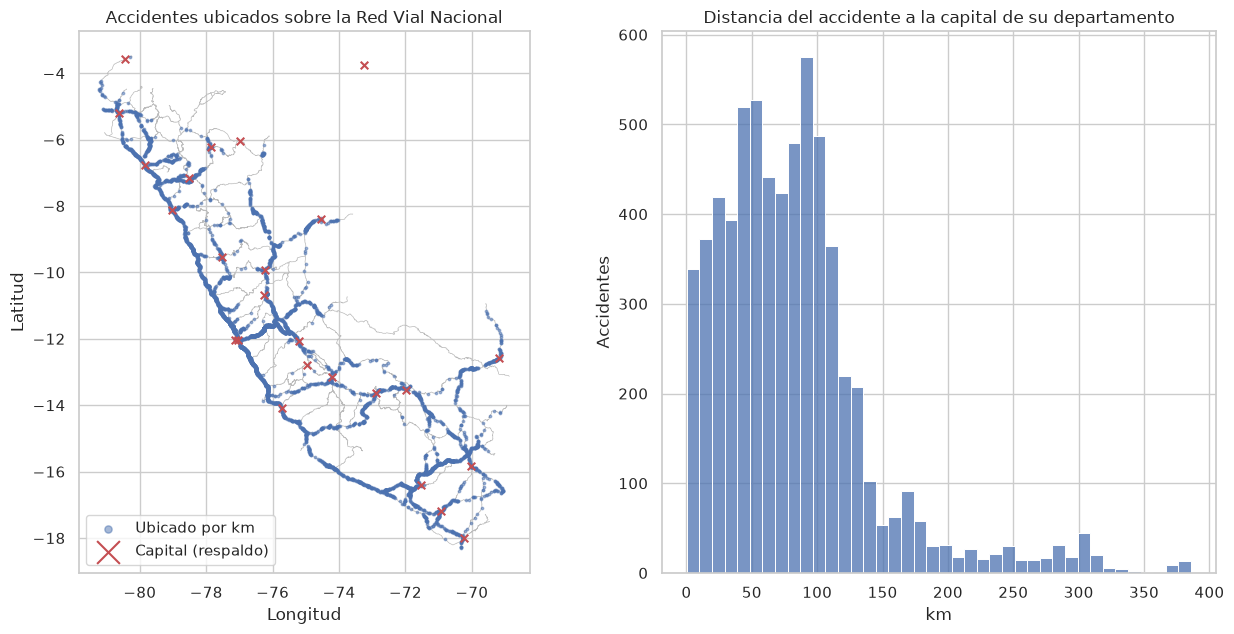

In [9]:
cap = np.array([pp.COORD[dep] for dep in df.DEPARTAMENTO])
df["DIST_CAPITAL_KM"] = pp.haversine_km(cap[:, 1], cap[:, 0], df.LON, df.LAT)
km_ok = df.UBICACION == "km"
print("Distancia del punto ubicado a la capital de su departamento (km):")
print(df.loc[km_ok, "DIST_CAPITAL_KM"].describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())
print("\nMediana por departamento (km):")
print(df[km_ok].groupby("DEPARTAMENTO").DIST_CAPITAL_KM.median().round(0).sort_values(ascending=False).head(8).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
for t in tramos:
    ax[0].plot(t["lon"], t["lat"], color="#BBBBBB", lw=0.5, zorder=1)
ax[0].scatter(df.loc[km_ok, "LON"], df.loc[km_ok, "LAT"], s=3, color="#4C72B0", alpha=.5, label="Ubicado por km", zorder=2)
caps = np.array(list(pp.COORD.values()))
ax[0].scatter(caps[:, 1], caps[:, 0], marker="x", s=30, color="#C44E52", label="Capital (respaldo)", zorder=3)
ax[0].set(title="Accidentes ubicados sobre la Red Vial Nacional", xlabel="Longitud", ylabel="Latitud", aspect="equal")
ax[0].legend(loc="lower left", markerscale=3)
sns.histplot(df.loc[km_ok, "DIST_CAPITAL_KM"], bins=40, ax=ax[1], color="#4C72B0")
ax[1].set(title="Distancia del accidente a la capital de su departamento", xlabel="km", ylabel="Accidentes")
plt.tight_layout(); plt.savefig(PLOTS / "prep_01_ubicacion.png", dpi=150); plt.show()

**Hallazgo:** en mediana el accidente está a **73 km** de su capital (p90: 143 km). Ej.: el accidente de 33 fallecidos queda en la Carretera Central a ~3 800 m, no en Lima.

## 3. Clima: precipitación diaria (Open-Meteo)

**Decisiones**
- Reanálisis de Open-Meteo (no estaciones) en la **celda de 0.1° (~11 km)** del accidente, que es la resolución real del modelo.
- Solo se piden los bloques de 14 días con accidentes en cada celda (límite gratuito de la API). Queda en caché en `data/raw/`.
- `timezone=America/Lima` para que el día coincida con `FECHA`.
- Se guarda también `ELEVACION` de la celda y la lluvia de la capital (`PRECIP_CAPITAL`) para comparar.

In [10]:
df["CELDA_LAT"], df["CELDA_LON"] = pp.asignar_celda(df.LAT, df.LON)
clima_cap = pp.cargar_clima(df)
clima = pp.cargar_clima_puntos(df)
print(f"Celdas con accidentes: {df[['CELDA_LAT', 'CELDA_LON']].drop_duplicates().shape[0]}")
print(f"Clima por celda: {len(clima):,} filas (celda-día) | {clima.FECHA.min().date()} → {clima.FECHA.max().date()}")
print(f"Clima de capitales: {len(clima_cap):,} filas | {clima_cap.DEPARTAMENTO.nunique()} departamentos")
clima[["precipitation_sum", "rain_sum", "precipitation_hours", "ELEVACION"]].describe().round(2)

Celdas con accidentes: 964
Clima por celda: 81,128 filas (celda-día) | 2020-01-01 → 2021-09-30
Clima de capitales: 15,975 filas | 25 departamentos


,precipitation_sum,rain_sum,precipitation_hours,ELEVACION
count,81128.00,81128.00,81128.00,81128.00
mean,2.01,1.89,3.86,1671.60
std,4.95,4.83,5.64,1700.25
min,0.00,0.00,0.00,-1.00
25%,0.00,0.00,0.00,134.00
50%,0.00,0.00,0.00,749.00
75%,1.70,1.50,6.00,3598.00
max,163.90,163.90,24.00,5013.00


In [11]:
# ¿precipitation_sum o rain_sum?
dif = clima.precipitation_sum - clima.rain_sum
print(f"Correlación precipitation_sum vs. rain_sum: {clima[['precipitation_sum', 'rain_sum']].corr().iloc[0, 1]:.4f}")
print(f"Celda-días en que difieren: {(dif > 0).sum()} ({100 * (dif > 0).mean():.2f} %)")
print(f"Altitud mediana de esas celdas: {clima.loc[dif > 0, 'ELEVACION'].median():.0f} m "
      f"(resto: {clima.loc[dif == 0, 'ELEVACION'].median():.0f} m)")
print("Valores distintos de cero más pequeños de precipitation_sum:",
      np.sort(clima.loc[clima.precipitation_sum > 0, "precipitation_sum"].unique())[:3])

Correlación precipitation_sum vs. rain_sum: 0.9890
Celda-días en que difieren: 5974 (7.36 %)
Altitud mediana de esas celdas: 4343 m (resto: 564 m)
Valores distintos de cero más pequeños de precipitation_sum: [0.1 0.2 0.3]


**Decisión:** usar `precipitation_sum` (correlación 0.989 con `rain_sum`); la diferencia es nieve o granizo en la puna, que también afecta la vía.

In [12]:
data = df.drop(columns="DIST_CAPITAL_KM").merge(clima_cap[["DEPARTAMENTO", "FECHA", "precipitation_sum"]].rename(columns={"precipitation_sum": "PRECIP_CAPITAL"}),
                on=["DEPARTAMENTO", "FECHA"], how="left")
data = data.merge(clima, on=["CELDA_LAT", "CELDA_LON", "FECHA"], how="left")
assert len(data) == len(df), "La unión no debe duplicar ni perder accidentes"
print(f"Accidentes con lluvia en su celda: {data.precipitation_sum.notna().mean():.1%} | "
      f"con lluvia de la capital: {data.PRECIP_CAPITAL.notna().mean():.1%}")

Accidentes con lluvia en su celda: 100.0% | con lluvia de la capital: 100.0%


**¿Cuánto cambia frente a la lluvia de la capital?**

Correlación lluvia en el punto vs. en la capital: 0.543
Diferencia absoluta (mm): mediana 0.20, p90 5.70


precipitation_sum,llueve en el punto,seco en el punto
PRECIP_CAPITAL,,
llueve en la capital,32.3,8.9
seco en la capital,13.5,45.3


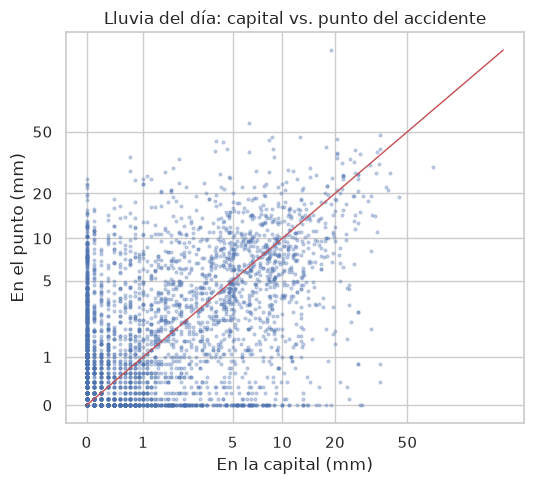

In [13]:
k = data[data.UBICACION == "km"]
llueve_punto, llueve_cap = k.precipitation_sum > 0.1, k.PRECIP_CAPITAL > 0.1
print(f"Correlación lluvia en el punto vs. en la capital: {k[['precipitation_sum', 'PRECIP_CAPITAL']].corr().iloc[0, 1]:.3f}")
print(f"Diferencia absoluta (mm): mediana {(k.precipitation_sum - k.PRECIP_CAPITAL).abs().median():.2f}, "
      f"p90 {(k.precipitation_sum - k.PRECIP_CAPITAL).abs().quantile(.9):.2f}")
display(pd.crosstab(llueve_cap.map({True: "llueve en la capital", False: "seco en la capital"}),
                    llueve_punto.map({True: "llueve en el punto", False: "seco en el punto"}), normalize="all").mul(100).round(1))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(np.log1p(k.PRECIP_CAPITAL), np.log1p(k.precipitation_sum), s=4, alpha=.3, color="#4C72B0")
lim = np.log1p(max(k.PRECIP_CAPITAL.max(), k.precipitation_sum.max()))
ax.plot([0, lim], [0, lim], color="#C44E52", lw=1)
ticks = [0, 1, 5, 10, 20, 50]
ax.set_xticks(np.log1p(ticks)); ax.set_xticklabels(ticks); ax.set_yticks(np.log1p(ticks)); ax.set_yticklabels(ticks)
ax.set(title="Lluvia del día: capital vs. punto del accidente", xlabel="En la capital (mm)", ylabel="En el punto (mm)")
plt.tight_layout(); plt.savefig(PLOTS / "prep_02_lluvia_punto_vs_capital.png", dpi=150); plt.show()

**Hallazgo:** la capital era un mal *proxy*: correlación **0.54** con la lluvia en el punto, y en el **22 %** de los accidentes no coinciden en si llovió.

## 4. Atributos de la vía (Red Vial Nacional del MTC)

Los papers revisados asocian la gravedad con las características de la vía: alineamiento, superficie,
configuración y velocidad (Babaoglu y Babaoglu, 2021; Emu et al., 2022). SUTRAN no las registra, pero la capa del MTC
que ya usamos para ubicar los accidentes trae 18 campos por tramo. `pp.ubicar_accidentes` copia los del tramo en el
que cae cada accidente y calcula la **sinuosidad** en ±1 km.

**Decisiones**
- La superficie viene codificada; los códigos se traducen con el dominio de la capa (`pp.SUPERFICIE`, consultado en el servicio).
- El 19.8 % de accidentes sin tramo (ubicados en la capital o en vías departamentales) lleva la categoría
  `SIN TRAMO`. No se imputa, porque esos accidentes no tienen un tramo conocido.
- Los 0 en carriles, ancho o velocidad son "sin dato" en la capa → NaN.
- La sinuosidad se limita a 3: unos pocos tramos mal dibujados llegan a 12.

In [14]:
print(f"Accidentes con atributos de vía: {(data.TOPOGRAFIA != pp.SIN_TRAMO).mean():.1%}")
for c in ["TOPOGRAFIA", "SUPERFICIE", "ESTADO_VIA", "REGION_NATURAL"]:
    print(f"{c}: {data[c].value_counts().to_dict()}")
data[["CARRILES", "ANCHO_CALZADA", "VEL_PROMEDIO_TRAMO", "SINUOSIDAD"]].describe().round(2)

Accidentes con atributos de vía: 80.2%
TOPOGRAFIA: {'PLANO': 3530, 'ONDULADO': 2125, 'SIN TRAMO': 1608, 'MONTANOSO': 844, 'SIN INFORMACION': 3}
SUPERFICIE: {'ASFALTADO': 6106, 'SIN TRAMO': 1608, 'AFIRMADO': 182, 'ASFALTADO ECONOMICO': 156, 'PROYECTADA': 31, 'SIN AFIRMAR': 20, 'TROCHA': 7}
ESTADO_VIA: {'BUENA': 5927, 'SIN TRAMO': 1608, 'REGULAR': 291, 'MALA': 161, 'MUY BUENA': 90, 'SIN INFORMACION': 33}
REGION_NATURAL: {'SIERRA': 2916, 'COSTA': 2828, 'SIN TRAMO': 1608, 'SELVA': 758}


,CARRILES,ANCHO_CALZADA,VEL_PROMEDIO_TRAMO,SINUOSIDAD
count,6293.00,6292.00,6417.00,6495.00
mean,2.22,7.87,69.28,1.16
std,0.69,1.98,11.57,0.35
min,1.00,1.00,26.34,1.00
25%,2.00,7.00,62.45,1.00
50%,2.00,7.20,69.78,1.03
75%,2.00,9.10,78.24,1.13
max,7.00,20.00,80.89,3.00


## 5. Clima por hora y condición de luz (Open-Meteo)

La lluvia diaria no dice si llovía **a la hora** del accidente. Para cada accidente con hora se descarga el clima
horario de su celda, en `data/raw/clima_horario_celdas.csv`.

**Decisiones**
- Open-Meteo resume en las HH:00 la hora previa. Por eso el accidente de las 14:35 se describe con el registro de las 15:00.
- `PRECIP_3H` (hora anterior, la del accidente y la siguiente) es un proxy de vía mojada, en la línea de Babaoglu, que
  imputa la superficie mojada a partir del clima.
- El código WMO se agrupa en las categorías de Mhetre y Thube (despejado, nublado, llovizna, lluvia, nieve). El
  reanálisis no reporta neblina como código, así que `NEBLINA` se aproxima con temperatura − punto de rocío < 2 °C.
- **Luz:** `ES_DE_DIA` compara la hora exacta (HH:MM) con la salida y la puesta del sol de ese día y lugar;
  `CREPUSCULO` = a ±1 h de alguna de las dos.
- Los 86 accidentes sin hora quedan con estas variables vacías (`SIN HORA` en las categóricas).

In [15]:
clima_h = pp.cargar_clima_horario(data)
data = data.join(pp.variables_clima_horario(data, clima_h))
con_hora = data.HORA_INT.notna()
print(f"Accidentes con hora: {con_hora.sum():,}; con clima por hora: {data.loc[con_hora, 'CLIMA_HORA'].notna().mean():.1%}")
print("CLIMA_HORA:", data.CLIMA_HORA.value_counts().to_dict())
print(f"De noche: {(data.ES_DE_DIA == 0).mean():.1%} · crepúsculo: {(data.CREPUSCULO == 1).mean():.1%} · neblina: {(data.NEBLINA == 1).mean():.1%}")

# Verificación manual: Lima, 01/01/2020 a las 05:40. El sol sale ≈ 05:45 → noche y crepúsculo
v = data[(data.FECHA == "2020-01-01") & (data.HORA.astype(str).str.startswith("05:40")) & (data.DEPARTAMENTO == "LIMA")]
assert (v.ES_DE_DIA == 0).all() and (v.CREPUSCULO == 1).all()
v[["FECHA", "HORA", "DEPARTAMENTO", "PRECIP_HORA", "CLIMA_HORA", "ES_DE_DIA", "CREPUSCULO"]]

Accidentes con hora: 8,024; con clima por hora: 100.0%
CLIMA_HORA: {'NUBLADO': 3844, 'DESPEJADO': 2685, 'LLOVIZNA': 1262, 'LLUVIA': 156, 'NIEVE': 77}
De noche: 41.3% · crepúsculo: 21.8% · neblina: 26.7%


,FECHA,HORA,DEPARTAMENTO,PRECIP_HORA,CLIMA_HORA,ES_DE_DIA,CREPUSCULO
0,2020-01-01,05:40,LIMA,0.0,NUBLADO,0.0,1.0


## 6. Variables derivadas

Sin fuentes externas (`pp.variables_derivadas`):
- **Calendario:** fin de semana, feriado nacional, **puente** (día dentro de ≥ 3 días seguidos no laborables) y cuarentena.
- **Distancia del punto a la capital del departamento.**
- **Tipo de vía:** nacional o departamental, según el código de la vía.

In [16]:
data = data.join(pp.variables_derivadas(data))
data[["FIN_DE_SEMANA", "FERIADO", "PUENTE", "CUARENTENA"]].mean().mul(100).round(1).rename("% de accidentes").to_frame().T

,FIN_DE_SEMANA,FERIADO,PUENTE,CUARENTENA
% de accidentes,30.2,2.7,2.7,6.6


## 7. Selección de variables y encoding (decisiones del grupo, 12/11/2026)

Con todas las variables, el one-hot de un modelo lineal producía **135 columnas** en la Tarea 2, de las cuales 34
venían de las 174 vías. Para que el encoding no sea excesivo, se decidió:

| Decisión | Variables | Motivo |
|---|---|---|
| **Eliminar del modelo** | `CODIGO_VIA` (queda solo como identificación) | 174 vías; la vía ya entra por los atributos del tramo y por el departamento |
| **Eliminar** | `FRANJA` | Repite la hora, que entra como seno/coseno |
| **Eliminar del modelo** | `DIA_SEMANA` (queda como identificación) | Ya está `FIN_DE_SEMANA` |
| **Eliminar** | `TEMPERATURA`, `VIENTO`, `NUBOSIDAD` | Sin respaldo en la bibliografía ni señal en el EDA |
| **Eliminar** | `LAT`, `LON` | Se superponen con el departamento y la distancia a la capital |
| **Ordinal** (una columna) | `TOPOGRAFIA` (plano < ondulado < montañoso), `ESTADO_VIA` (muy buena → mala), `SUPERFICIE` (asfaltado → trocha) | Tienen orden natural; `SIN TRAMO` queda vacío y se imputa con la mediana (`UBICACION` ya marca "sin tramo") |
| **One-hot** | `DEPARTAMENTO` (23), `MODALIDAD`, `CLIMA_HORA`, `REGION_NATURAL`, `TIPO_VIA`; binarias (`UBICACION`) en una sola columna | Sin orden natural; las categorías con < 30 casos se agrupan |

El encoding no se guarda en el CSV: se aplica dentro del pipeline de cada modelo (`src/models.py::preprocesador`, que usa
`ORDINALES`), para que se ajuste solo con los datos de entrenamiento de cada pliegue. Resultado: **67 columnas** en la
Tarea 2 y 43 en la Tarea 1.

## 8. Dataset final de la Tarea 2 (`data/processed/accidentes.csv`)

`data` arrastra todas las columnas intermedias: el crudo, la celda, el motivo de la ubicación, `rain_sum`, la lluvia
de la capital, el texto de la hora, el kilómetro, etc. El dataset final se queda solo con **identificación, objetivo y
variables**, con nombres legibles (`pp.COLUMNAS_FINALES`), y sin los 5 accidentes de gravedad desconocida.

In [17]:
final = pp.dataset_final(data)
print(f"De {data.shape[1]} columnas intermedias a {final.shape[1]} finales; {len(final):,} accidentes")
print("Columnas que se descartan:", sorted(set(data.columns) - {c for c, _ in pp.COLUMNAS_FINALES.values()}))
final.to_csv(pp.F_DATASET, index=False)
print("Guardado:", pp.F_DATASET.relative_to(ROOT))
pd.DataFrame([(c, d, str(final[c].dtype), f"{final[c].notna().mean():.1%}") for c, (_, d) in pp.COLUMNAS_FINALES.items()],
             columns=["columna", "descripción", "tipo", "con dato"])

De 46 columnas intermedias a 33 finales; 8,105 accidentes
Columnas que se descartan: ['ANIO', 'CELDA_LAT', 'CELDA_LON', 'ES_FATAL', 'FECHA_CORTE', 'HORA', 'KILOMETRO', 'LAT', 'LON', 'MOTIVO_UBICACION', 'PRECIP_CAPITAL', 'PRECIP_HORA', 'rain_sum']


Guardado: data/processed/accidentes.csv


,columna,descripción,tipo,con dato
0,FECHA,Fecha del accidente,datetime64[us],100.0%
1,HORA,Hora entera 0-23 (vacía si SUTRAN no la registró),float64,98.9%
2,MES,Mes 1-12,int32,100.0%
3,DIA_SEMANA,0 = lunes … 6 = domingo,int32,100.0%
4,DEPARTAMENTO,"Departamento (SUTRAN, normalizado)",str,100.0%
5,CODIGO_VIA,Código de la vía (SUTRAN),str,100.0%
6,TIPO_VIA,NACIONAL / DEPARTAMENTAL / SIN DATO,str,100.0%
7,UBICACION,km = ubicado sobre la vía; capital = respaldo ...,str,100.0%
8,NUM_FALLECIDOS,Fallecidos (SUTRAN),int64,100.0%
9,NUM_HERIDOS,Heridos (SUTRAN),int64,100.0%


## 9. Panel departamento × día de la Tarea 1 (`data/processed/panel_depto_dia.csv`)

El registro solo trae días **con** accidentes. El panel cruza los 24 departamentos (Callao se une a Lima, que lo
rodea) con los 639 días y pone `N_ACC = 0` en los días sin accidentes.

**Decisiones**
- **Clima:** lluvia en la capital del departamento, porque la unidad es el departamento. Supuesto: el día *t* se conoce por el pronóstico.
- **Historia:** conteos, fatales, heridos y mezcla de modalidades, todos **desplazados un día**, para que el pronóstico
  del día *t* solo use información hasta *t − 1*.

In [18]:
panel = pp.construir_panel(data, clima_cap)
assert len(panel) == 24 * 639 and panel.N_ACC.sum() == len(data), "el panel debe tener todos los días y todos los accidentes"
lima = panel[panel.DEPARTAMENTO == "LIMA"].reset_index(drop=True)
assert abs(lima.N_ACC_M7[100] - lima.N_ACC[93:100].mean()) < 1e-9 and lima.N_ACC_AYER[100] == lima.N_ACC[99], "fuga temporal"
print(f"Guardado: {pp.F_PANEL.relative_to(ROOT)} {panel.shape}")
print(f"Departamento-días con ≥ 1 accidente: {(panel.N_ACC > 0).mean():.1%} · con alguno fatal: {panel.HAY_FATAL.mean():.1%}")
panel.head()

Guardado: data/processed/panel_depto_dia.csv (15336, 25)
Departamento-días con ≥ 1 accidente: 33.9% · con alguno fatal: 5.8%


,DEPARTAMENTO,FECHA,PRECIP,HORAS_LLUVIA,N_ACC,N_FATALES,HAY_FATAL,PRECIP_PREV3,PRECIP_PREV7,N_ACC_AYER,N_ACC_SEMANA_PASADA,N_ACC_M7,N_ACC_M28,N_FATALES_M28,N_HERIDOS_M28,P_ATROPELLO_M28,P_CHOQUE_M28,FIN_DE_SEMANA,FERIADO,PUENTE,CUARENTENA,DIA_SEMANA,MES_SIN,MES_COS,ALTITUD_MEDIA
0,AMAZONAS,2020-01-01,1.2,6.0,1.0,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0,1,0,0,2,0.5,0.866025,1768.0
1,AMAZONAS,2020-01-02,1.0,9.0,1.0,0.0,0,1.2,1.2,1.0,NaN,0.142857,0.035714,0.0,0.071429,0.0,0.0,0,0,0,0,3,0.5,0.866025,1768.0
2,AMAZONAS,2020-01-03,0.4,4.0,0.0,0.0,0,2.2,2.2,1.0,NaN,0.285714,0.071429,0.0,0.107143,0.0,0.0,0,0,0,0,4,0.5,0.866025,1768.0
3,AMAZONAS,2020-01-04,2.0,2.0,0.0,0.0,0,2.6,2.6,0.0,NaN,0.285714,0.071429,0.0,0.107143,0.0,0.0,1,0,0,0,5,0.5,0.866025,1768.0
4,AMAZONAS,2020-01-05,0.2,2.0,0.0,0.0,0,3.4,4.6,0.0,NaN,0.285714,0.071429,0.0,0.107143,0.0,0.0,1,0,0,0,6,0.5,0.866025,1768.0
